# E — RQ3: Reliability–Cost Trade-off Analysis

**DSA4213 Group 15 · Contributor E**

Answers the question:
> Does the accuracy improvement from M1 → M5 justify the additional LLM cost?

**All numbers in this notebook come from the saved JSONL records — nothing is
hand-computed or fabricated.**  When running on mock data the results are
illustrative only; replace `OUTPUT_JSONL` with a real experiment file to get
actual research results.

> ⚠️ Cells tagged **[SYNTHETIC MOCK DATA]** use randomly generated examples
> and canned model responses.  Do not cite these numbers as experimental results.


In [1]:
import sys, os, dataclasses, tempfile, pathlib

# Allow running the notebook from the research/ subdirectory.
_repo_root = pathlib.Path(__file__).resolve().parent.parent if "__file__" in dir() else pathlib.Path.cwd().parent
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.runner.mocks import (
    MockDraftPort, MockRetrievePort, MockClaimsPort,
    MockVerificationPort, MockLLMClient, make_synthetic_example,
)
from src.runner.runner import ExperimentRunner
from src.runner.records import load_records
from src.evaluation.answer_metrics import compute_em_f1_batch
from src.evaluation.retrieval_metrics import mean_recall_at_k, RecallDenominator
from src.evaluation.cost_metrics import (
    aggregate_usage_by_method, aggregate_draft_usage, estimate_budget,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Imports OK")


Imports OK


In [2]:
# ── Configuration ─────────────────────────────────────────────────────────
METHOD_IDS  = ["M1", "M2", "M3", "M4", "M5"]
METHOD_DESC = {
    "M1": "Direct",
    "M2": "Self-Reflection",
    "M3": "Independent Critic",
    "M4": "Evidence-Draft",
    "M5": "Atomic-Claim",
}
COLORS = {"M1": "#4C72B0", "M2": "#DD8452", "M3": "#55A868", "M4": "#C44E52", "M5": "#8172B2"}
RECALL_K   = 5
OUTPUT_JSONL = str(pathlib.Path(tempfile.mkdtemp()) / "e_mock_records.jsonl")
print(f"Output file: {OUTPUT_JSONL}")


Output file: C:\Users\ROG\AppData\Local\Temp\tmp_6hc5y78\e_mock_records.jsonl


## 1. Generate Synthetic Records [SYNTHETIC MOCK DATA]

Creates 5 examples where different methods score differently on EM:
- **e00–e02** gold = `"The mock answer"` → M1 scores 1.0 EM (draft output matches)
- **e03–e04** gold = `"The revised mock answer"` → M3/M4/M5 score 1.0 EM (revision output matches)

Replace this section with `load_records(PATH_TO_REAL_JSONL)` for real experiments.

In [3]:
# ── Build synthetic examples with calibrated gold answers ─────────────────
EXAMPLES    = []
GOLD_LOOKUP = {}

for i in range(3):           # M1's draft matches gold
    eid = f"e{i:02d}"
    EXAMPLES.append(make_synthetic_example(eid, f"Q{i}: What is the capital of France?"))
    GOLD_LOOKUP[eid] = {
        "example_id": eid,
        "gold_answer": "The mock answer",
        "gold_supporting_facts": [{"title": "France", "sentence_id": 0}],
    }

for i in range(3, 5):        # M3/M4/M5 revision output matches gold
    eid = f"e{i:02d}"
    EXAMPLES.append(make_synthetic_example(eid, f"Q{i}: What country is Paris in?"))
    GOLD_LOOKUP[eid] = {
        "example_id": eid,
        "gold_answer": "The revised mock answer",
        "gold_supporting_facts": [{"title": "France", "sentence_id": 0}],
    }

for eid, g in GOLD_LOOKUP.items():
    print(f"  {eid}: gold='{g['gold_answer']}'")


  e00: gold='The mock answer'
  e01: gold='The mock answer'
  e02: gold='The mock answer'
  e03: gold='The revised mock answer'
  e04: gold='The revised mock answer'


In [4]:
# ── Run ExperimentRunner ──────────────────────────────────────────────────
runner = ExperimentRunner(
    draft_port=MockDraftPort(),
    retrieve_port=MockRetrievePort(),
    claims_port=MockClaimsPort(),
    verification_port=MockVerificationPort(),
    llm=MockLLMClient(model="mock-model-v1"),
    top_k=RECALL_K,
)
new_recs = runner.run(
    EXAMPLES, OUTPUT_JSONL,
    model_settings={"model": "mock-model-v1", "temperature": 0.0},
)
print(f"Generated {len(new_recs)} records → {OUTPUT_JSONL}")


Generated 25 records → C:\Users\ROG\AppData\Local\Temp\tmp_6hc5y78\e_mock_records.jsonl


## 2. Load Records

In [5]:
records = load_records(OUTPUT_JSONL)
record_dicts = [dataclasses.asdict(r) for r in records]
print(f"Loaded {len(records)} records ({len(EXAMPLES)} examples × {len(METHOD_IDS)} methods)")

df_preview = pd.DataFrame([{
    "example_id":    r.example_id,
    "method_id":     r.method_id,
    "status":        r.status,
    "final_answer":  (r.final_answer or "")[:40],
    "method_calls":  len(r.usage),
    "draft_calls":   len(r.draft_usage),
} for r in records]).sort_values(["example_id", "method_id"])
print(df_preview.to_string(index=False))


Loaded 25 records (5 examples × 5 methods)
example_id method_id status                  final_answer  method_calls  draft_calls
       e00        M1     ok              The mock answer.             0            1
       e00        M2     ok The revised mock answer (M2).             1            1
       e00        M3     ok      The revised mock answer.             2            1
       e00        M4     ok      The revised mock answer.             2            1
       e00        M5     ok      The revised mock answer.             3            1
       e01        M1     ok              The mock answer.             0            1
       e01        M2     ok The revised mock answer (M2).             1            1
       e01        M3     ok      The revised mock answer.             2            1
       e01        M4     ok      The revised mock answer.             2            1
       e01        M5     ok      The revised mock answer.             3            1
       e02        M1  

## 3. Official Evaluation Metrics (EM / F1 / Recall@k)

- EM and token F1 follow the HotpotQA official evaluation script normalization.
- Recall@k uses **question-conditioned** denominator (all gold supporting facts).
  Claim-conditioned Recall@k requires a claim→gold mapping not yet available (see GAP-7).
- Failed records (`status != "ok"`) count as 0 in numerator but stay in denominator.

In [6]:
em_f1 = compute_em_f1_batch(record_dicts, GOLD_LOOKUP)
print("EM / F1 per method:")
print(f"  {'Method':<6} {'EM':>6} {'F1':>6} {'n':>4} {'ok':>4} {'err':>4}")
print("  " + "-" * 36)
for mid in METHOD_IDS:
    d = em_f1.get(mid, {})
    print(f"  {mid:<6} {d.get('em', 0):>6.3f} {d.get('f1', 0):>6.3f} "
          f"{d.get('n', 0):>4} {d.get('n_ok', 0):>4} {d.get('n_error', 0):>4}")


EM / F1 per method:
  Method     EM     F1    n   ok  err
  ------------------------------------
  M1      0.600  0.920    5    5    0
  M2      0.000  0.743    5    5    0
  M3      0.400  0.880    5    5    0
  M4      0.400  0.880    5    5    0
  M5      0.400  0.880    5    5    0


In [7]:
recall_results = {}
for mid in ["M4", "M5"]:
    r = mean_recall_at_k(record_dicts, GOLD_LOOKUP, k=RECALL_K,
                         method_id=mid,
                         denominator=RecallDenominator.QUESTION_CONDITIONED)
    recall_results[mid] = r
    print(f"{mid} Recall@{RECALL_K} (question-conditioned): "
          f"{r['mean_recall']:.3f}  (n={r['n']}, ok={r['n_ok']}, err={r['n_error']})")
print("M1/M2/M3: Recall@k not applicable — no evidence retrieved in these conditions.")


M4 Recall@5 (question-conditioned): 1.000  (n=5, ok=5, err=0)
M5 Recall@5 (question-conditioned): 1.000  (n=5, ok=5, err=0)
M1/M2/M3: Recall@k not applicable — no evidence retrieved in these conditions.


## 4. Cost and Usage Analysis

`draft_usage` (shared `generate_draft` call) is kept separate from method-specific
usage to avoid 5× double-counting when comparing methods.  Set real unit prices in
`configs/model_pricing.json` before a real run; mock prices are $0.00.

In [8]:
usage_by_method = aggregate_usage_by_method(record_dicts, include_draft_usage=False)
draft_agg       = aggregate_draft_usage(record_dicts)

print("Method-specific LLM usage:")
print(f"  {'Method':<6} {'Calls':>7} {'In-Tok':>8} {'Out-Tok':>9} {'Cost(USD)':>11} {'Lat(ms)':>9} {'Cache':>6}")
print("  " + "-" * 60)
for mid in METHOD_IDS:
    d = usage_by_method.get(mid, {})
    cost  = d.get("cost_usd_sum")
    lat   = d.get("mean_latency_ms")
    itok  = d.get("input_tokens_sum")
    otok  = d.get("output_tokens_sum")
    cache = d.get("cache_hits", 0)
    print(f"  {mid:<6} {d.get('llm_calls', 0):>7} "
          f"{str(itok) if itok is not None else 'N/A':>8} "
          f"{str(otok) if otok is not None else 'N/A':>9} "
          f"{'$'+f'{cost:.6f}' if cost is not None else 'N/A':>11} "
          f"{f'{lat:.1f}' if lat is not None else 'N/A':>9} "
          f"{cache:>6}")

print()
dcost = draft_agg.get("cost_usd_sum")
print(f"Shared draft (generate_draft, once per example): "
      f"{'$'+f'{dcost:.6f}' if dcost is not None else 'N/A'} "
      f"across {draft_agg['n_examples']} examples")


Method-specific LLM usage:
  Method   Calls   In-Tok   Out-Tok   Cost(USD)   Lat(ms)  Cache
  ------------------------------------------------------------
  M1           0      N/A       N/A         N/A       N/A      0
  M2           5      250       400   $0.000650     120.0      0
  M3          10      500       800   $0.001300     120.0      0
  M4          10      500       800   $0.001300     120.0      0
  M5          15      750      1200   $0.001950     120.0      0

Shared draft (generate_draft, once per example): $0.000650 across 5 examples


In [9]:
# ── Combined summary table ────────────────────────────────────────────────
rows = []
for mid in METHOD_IDS:
    em_d    = em_f1.get(mid, {})
    u       = usage_by_method.get(mid, {})
    rec_d   = recall_results.get(mid, {})
    cost_ex = u.get("per_example_cost_usd")
    rows.append({
        "Method":         f"{mid} {METHOD_DESC[mid]}",
        "EM":             round(em_d.get("em", 0), 3),
        "F1":             round(em_d.get("f1", 0), 3),
        f"Recall@{RECALL_K}": f"{rec_d['mean_recall']:.3f}" if mid in recall_results else "N/A",
        "LLM Calls":      u.get("llm_calls", 0),
        "Cost/Ex (USD)":  f"${cost_ex:.6f}" if cost_ex is not None else "N/A",
        "Latency (ms)":   f"{u['mean_latency_ms']:.1f}" if u.get("mean_latency_ms") else "N/A",
        "Cache Hits":     u.get("cache_hits", 0),
    })

df_summary = pd.DataFrame(rows).set_index("Method")
print("=== RESULTS SUMMARY  [SYNTHETIC MOCK DATA — not real experimental results] ===")
print(df_summary.to_string())


=== RESULTS SUMMARY  [SYNTHETIC MOCK DATA — not real experimental results] ===
                        EM     F1 Recall@5  LLM Calls Cost/Ex (USD) Latency (ms)  Cache Hits
Method                                                                                      
M1 Direct              0.6  0.920      N/A          0           N/A          N/A           0
M2 Self-Reflection     0.0  0.743      N/A          5     $0.000130        120.0           0
M3 Independent Critic  0.4  0.880      N/A         10     $0.000260        120.0           0
M4 Evidence-Draft      0.4  0.880    1.000         10     $0.000260        120.0           0
M5 Atomic-Claim        0.4  0.880    1.000         15     $0.000390        120.0           0


## 5. Visualisations

Generated from the loaded records.  Labels marked **[MOCK]** indicate synthetic data.
In a real run, replace OUTPUT_JSONL with the actual results path.

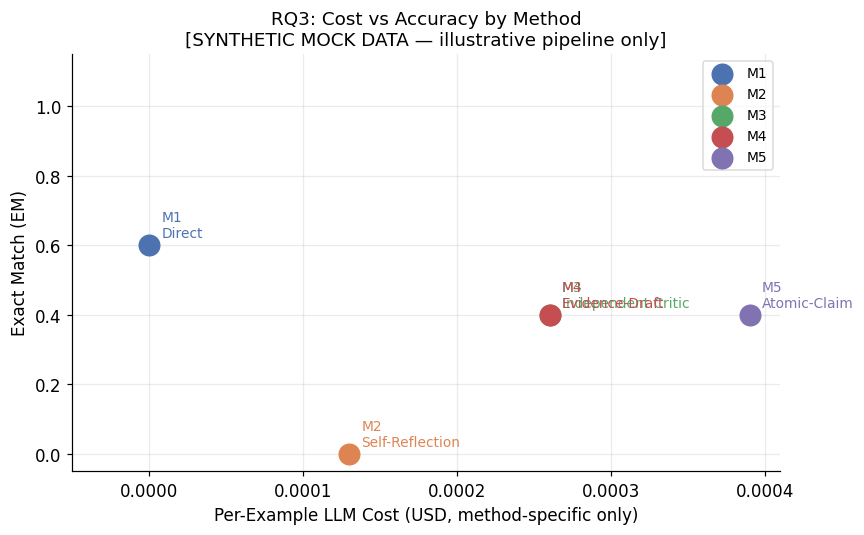

Saved E_cost_vs_em.png


In [10]:
# ── Plot 1: Cost vs EM scatter ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 5))

for mid in METHOD_IDS:
    em_d = em_f1.get(mid, {})
    u    = usage_by_method.get(mid, {})
    x    = u.get("per_example_cost_usd") or 0.0
    y    = em_d.get("em", 0.0)
    ax.scatter(x, y, color=COLORS[mid], s=180, zorder=5, label=mid)
    ax.annotate(f"{mid}\n{METHOD_DESC[mid]}", (x, y),
                textcoords="offset points", xytext=(8, 5), fontsize=9,
                color=COLORS[mid])

ax.set_xlabel("Per-Example LLM Cost (USD, method-specific only)")
ax.set_ylabel("Exact Match (EM)")
ax.set_title("RQ3: Cost vs Accuracy by Method\n"
             "[SYNTHETIC MOCK DATA — illustrative pipeline only]",
             fontsize=12)
ax.set_xlim(left=-max(0.00005, ax.get_xlim()[1] * 0.05))
ax.set_ylim(-0.05, 1.15)
ax.grid(True, alpha=0.25)
ax.legend(loc="upper right", fontsize=9, framealpha=0.7)

plt.tight_layout()
plt.savefig(str(pathlib.Path(OUTPUT_JSONL).parent / "E_cost_vs_em.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved E_cost_vs_em.png")


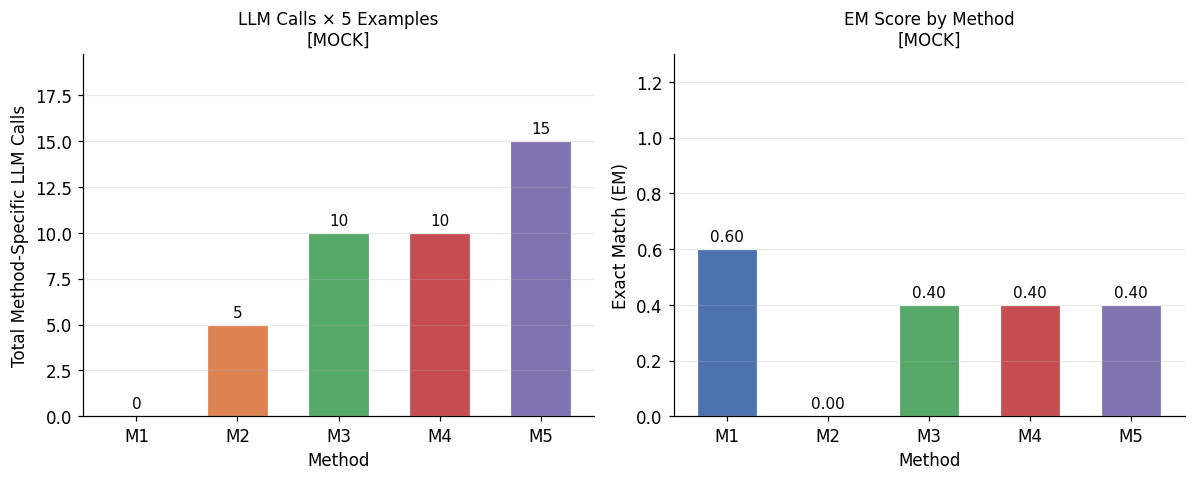

Saved E_calls_and_em.png


In [11]:
# ── Plot 2: LLM calls per method ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Left: total method-specific LLM calls
calls  = [usage_by_method.get(m, {}).get("llm_calls", 0) for m in METHOD_IDS]
colors = [COLORS[m] for m in METHOD_IDS]
bars = axes[0].bar(METHOD_IDS, calls, color=colors, width=0.6, edgecolor="white", lw=0.8)
axes[0].bar_label(bars, padding=3, fontsize=10)
axes[0].set_xlabel("Method")
axes[0].set_ylabel("Total Method-Specific LLM Calls")
axes[0].set_title(f"LLM Calls × {len(EXAMPLES)} Examples\n[MOCK]", fontsize=11)
axes[0].grid(True, axis="y", alpha=0.25)
axes[0].set_ylim(0, max(calls) * 1.25 + 1)

# Right: EM bar chart per method
ems    = [em_f1.get(m, {}).get("em", 0) for m in METHOD_IDS]
bars2 = axes[1].bar(METHOD_IDS, ems, color=colors, width=0.6, edgecolor="white", lw=0.8)
axes[1].bar_label(bars2, labels=[f"{v:.2f}" for v in ems], padding=3, fontsize=10)
axes[1].set_xlabel("Method")
axes[1].set_ylabel("Exact Match (EM)")
axes[1].set_title("EM Score by Method\n[MOCK]", fontsize=11)
axes[1].grid(True, axis="y", alpha=0.25)
axes[1].set_ylim(0, 1.3)

plt.tight_layout()
plt.savefig(str(pathlib.Path(OUTPUT_JSONL).parent / "E_calls_and_em.png"),
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved E_calls_and_em.png")


## 6. Budget Estimation

Scales trial per-example cost to a target study size.  The estimate is
`None` wherever cost data is missing (never fabricated).
Set real unit prices in `configs/model_pricing.json` before using this.
mock-model-v1 uses $0.00 prices, so estimates below are $0 — expected.

In [12]:
TARGET_N = 300
budget   = estimate_budget(record_dicts, target_n_examples=TARGET_N)

print(f"Trial size  : {budget['trial_n_examples']} examples")
print(f"Target size : {budget['target_n_examples']} examples")
print()

def _fmt_cost(v):
    return f"${v:.6f}" if v is not None else "N/A"

def _fmt_cost4(v):
    return f"${v:.4f}" if v is not None else "N/A"

budget_rows = []
for mid in METHOD_IDS:
    m = budget["methods"].get(mid, {})
    budget_rows.append({
        "Method":            mid,
        "Trial Cost":        _fmt_cost(m.get("trial_cost_usd")),
        "Per-Ex Cost":       _fmt_cost(m.get("per_example_cost_usd")),
        "Est. @ 300 ex":     _fmt_cost4(m.get("estimated_cost_usd")),
        "Est. LLM Calls":    m.get("estimated_calls", 0),
    })

df_budget = pd.DataFrame(budget_rows).set_index("Method")
print(df_budget.to_string())

d = budget["draft"]
print(f"\nShared draft @ {TARGET_N} examples: {_fmt_cost4(d.get('estimated_cost_usd'))}")
total = budget.get("total_estimated_cost_usd")
print(f"Grand total (all methods + draft): {_fmt_cost4(total)}")
print("\n[Note: mock-model-v1 has $0 unit prices — update configs/model_pricing.json for real estimates]")


Trial size  : 5 examples
Target size : 300 examples

       Trial Cost Per-Ex Cost Est. @ 300 ex  Est. LLM Calls
Method                                                     
M1            N/A         N/A           N/A               0
M2      $0.000650   $0.000130       $0.0390             300
M3      $0.001300   $0.000260       $0.0780             600
M4      $0.001300   $0.000260       $0.0780             600
M5      $0.001950   $0.000390       $0.1170             900

Shared draft @ 300 examples: $0.0390
Grand total (all methods + draft): N/A

[Note: mock-model-v1 has $0 unit prices — update configs/model_pricing.json for real estimates]


## 7. Limitations and Next Steps

### Current limitations (mock run)
- All outputs are from **synthetic mock data** — no real LLM inference.
- `mock-model-v1` has $0 unit prices, so all cost estimates are $0.
- EM/F1 values are calibrated to show method variation but do not reflect real model quality.
- Recall@k for M4/M5 = 1.0 because `MockRetrievePort` always returns the target sentence at rank 1.
- Claim-conditioned Recall@k is not computed (GAP-7: no claim→gold mapping available yet).

### To run on real data
1. Obtain a real experiment JSONL from `ExperimentRunner.run()` with real ports wired in.
2. Set `OUTPUT_JSONL = "path/to/real_records.jsonl"` in the config cell.
3. Update `configs/model_pricing.json` with actual provider prices.
4. Re-run all cells.  All analysis code is unchanged.

### Interface requirements for real integration
| Item | Owner | Status |
|------|-------|--------|
| `contracts/schemas.py` | Team | Missing — see GAP-2 |
| Dev/eval split manifest | B | Missing — see GAP-3 |
| `LLMResponse.usage` schema | C | Unconfirmed — see GAP-4 |
| Claim→gold mapping for Recall@k | B + C + E | Future work — see GAP-7 |
